In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from pyproj import Transformer
from shapely.geometry import Point, Polygon
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch, Rectangle
import seaborn as sns
from cartopy import feature as cf
from cartopy import crs as ccrs
from tqdm import tqdm
from cmocean import plots, cm
import cmcrameri.cm as cmr
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib.ticker import FuncFormatter

In [ ]:
# ---------------------------------------------------------------------------
# CONFIG — paths + the scenario this figure depicts (new scenario x beta sweep).
# ---------------------------------------------------------------------------
ROOT    = Path('..')
DATA    = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'

SCENARIO = 'BAU'      # Fig-1 shows the business-as-usual scenario
BETA     = 0.00       # conservation-priority weight; BAU signpost sits at beta=0
RES      = '50km'

# Per-combo rasters carry all 3 sensitivity dims (Demand-Reserve-Area).
# Keep anti-diagonal combinations as references; reported bounds use all 27 outcomes.
DRA_MID = 'DM-RM-AM'  # central (Demand=Median, Reserve=Median, Area=Median)
DRA_LO  = 'DL-RH-AL'  # reference: low demand, high reserve, low area-CI
DRA_HI  = 'DH-RL-AH'  # reference: high demand, low reserve, high area-CI

# Shared sensitivity combinations for panels c and d.
DRA_COMBINATIONS = [f'D{d}-R{r}-A{a}'
                    for d in ('L', 'M', 'H')
                    for r in ('L', 'M', 'H')
                    for a in ('L', 'M', 'H')]

FIG_OUT = FIGURES / 'Figure-1.png'

# --- new-layout path builders (dra defaults to the central case) -----------
def mine_path(dra=DRA_MID, scenario=SCENARIO, beta=BETA):
    return RESULTS / 'mining-area' / f'mining-area-expansion-2050-{scenario}-B{beta:.2f}-{RES}-{dra}.tif'

def risk_tif(dra=DRA_MID, scenario=SCENARIO, beta=BETA):
    return RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-{scenario}-B{beta:.2f}-{RES}-{dra}.tif'

def risk_csv(dra=DRA_MID, scenario=SCENARIO, beta=BETA):
    return RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-{scenario}-B{beta:.2f}-{RES}-{dra}.csv'

COUNTRY_RASTER  = RESULTS / 'country-rasters' / f'country-raster-eck4-{RES}.tif'
BIOME_RASTER    = RESULTS / 'biome-rasters' / f'biome-raster-eck4-{RES}.tif'
RWR_RASTER      = RESULTS / 'area-of-habitat-50km' / 'rarity-weighted-richness-vertebrates-50km.tif'
WORLD_MAP       = DATA / 'simplified-world-map' / 'world-map.shp'
EXTRACTION_XLSX = RESULTS / 'material-flows' / 'results-from-IMAGINE-Concrete.xlsx' 

In [ ]:
results_extraction = pd.read_excel(EXTRACTION_XLSX, sheet_name='extraction')

In [ ]:
def calculate_global_total(df, variable, scenario, statistic):
    df1 = df[(df['scenario'] == scenario) & (df['statistic'] == statistic) & (df['variable'] == variable)]
    yearly_sum = df1.groupby('year', as_index=False)['value'].sum().set_index('year')

    return yearly_sum

In [ ]:
global_sand_extraction_BAU_med = calculate_global_total(results_extraction, 'sand extraction', SCENARIO, 'median')
global_sand_extraction_BAU_low = calculate_global_total(results_extraction, 'sand extraction', SCENARIO, 'low')
global_sand_extraction_BAU_upp = calculate_global_total(results_extraction, 'sand extraction', SCENARIO, 'upper')

global_gravel_extraction_BAU_med = calculate_global_total(results_extraction, 'gravel extraction', SCENARIO, 'median')
global_gravel_extraction_BAU_low = calculate_global_total(results_extraction, 'gravel extraction', SCENARIO, 'low')
global_gravel_extraction_BAU_upp = calculate_global_total(results_extraction, 'gravel extraction', SCENARIO, 'upper')

global_limestone_extraction_BAU_med = calculate_global_total(results_extraction, 'limestone extraction', SCENARIO, 'median')
global_limestone_extraction_BAU_low = calculate_global_total(results_extraction, 'limestone extraction', SCENARIO, 'low')
global_limestone_extraction_BAU_upp = calculate_global_total(results_extraction, 'limestone extraction', SCENARIO, 'upper')

In [ ]:
country_raster_50km_            = rio.open(COUNTRY_RASTER)
biome_raster_50km               = rio.open(BIOME_RASTER).read(1)
rarity_weighted_richness_50km   = rio.open(RWR_RASTER).read(1)
mining_area_2050_BAU_50km       = rio.open(mine_path()).read(1)
mining_area_2050_BAU_50km_lower = rio.open(mine_path(DRA_LO)).read(1)
mining_area_2050_BAU_50km_upper = rio.open(mine_path(DRA_HI)).read(1)
affected_species_range_BAU_50km = rio.open(risk_tif()).read(1)
country_raster_50km             = country_raster_50km_.read(1)

In [ ]:
ASR_by_taxon_BAU       = pd.read_csv(risk_csv(), index_col=0)
ASR_by_taxon_BAU_lower = pd.read_csv(risk_csv(DRA_LO), index_col=0)
ASR_by_taxon_BAU_upper = pd.read_csv(risk_csv(DRA_HI), index_col=0)

# Figure 1d: each point is the total across Red List categories for one
# taxonomic group under one of the same 27 model sensitivity combinations.
ASR_factorial_by_taxon = pd.DataFrame(index=DRA_COMBINATIONS,
                                     columns=ASR_by_taxon_BAU.columns, dtype=float)
for dra in DRA_COMBINATIONS:
    overlap = pd.read_csv(risk_csv(dra), index_col=0)
    if (not overlap.index.equals(ASR_by_taxon_BAU.index)
            or not overlap.columns.equals(ASR_by_taxon_BAU.columns)):
        raise ValueError(f'Figure 1d category or taxon mismatch: {dra}')
    if not np.isfinite(overlap.to_numpy()).all():
        raise ValueError(f'Figure 1d non-finite overlap values: {dra}')
    ASR_factorial_by_taxon.loc[dra] = overlap.sum(axis=0)

assert ASR_factorial_by_taxon.shape == (27, 4)
for dra, expected in [(DRA_MID, ASR_by_taxon_BAU),
                      (DRA_LO, ASR_by_taxon_BAU_lower),
                      (DRA_HI, ASR_by_taxon_BAU_upper)]:
    np.testing.assert_allclose(ASR_factorial_by_taxon.loc[dra], expected.sum(axis=0))

# Take extrema after summing categories within each taxon.
ASR_total_by_taxon = ASR_factorial_by_taxon.loc[DRA_MID]
ASR_total_by_taxon_lower = ASR_factorial_by_taxon.min(axis=0)
ASR_total_by_taxon_upper = ASR_factorial_by_taxon.max(axis=0)
# Global bounds likewise require one global total per combination first.
ASR_factorial_global = ASR_factorial_by_taxon.sum(axis=1)


In [ ]:
world_map      = gpd.read_file(WORLD_MAP)
world_map      = world_map.drop([31])
world_map_eck4 = world_map.to_crs('ESRI:54012')

In [ ]:
biome_types       = [i for i in range(1, 15)]
MA_by_biome       = [mining_area_2050_BAU_50km[(biome_raster_50km == i) & (mining_area_2050_BAU_50km > 0)] for i in biome_types]
MA_by_biome_lower = [mining_area_2050_BAU_50km_lower[(biome_raster_50km == i) & (mining_area_2050_BAU_50km_lower > 0)] for i in biome_types]
MA_by_biome_upper = [mining_area_2050_BAU_50km_upper[(biome_raster_50km == i) & (mining_area_2050_BAU_50km_upper > 0)] for i in biome_types]
MA_prop_by_biome  = [100 * np.sum(a) / (np.nansum(mining_area_2050_BAU_50km))  for a in MA_by_biome]
MA_abs_by_biome   = [np.sum(a) for a in MA_by_biome]
MA_abs_by_biome_lower   = [np.sum(a) for a in MA_by_biome_lower]
MA_abs_by_biome_upper   = [np.sum(a) for a in MA_by_biome_upper]

# Figure 1c: all 3 x 3 x 3 demand/reserve/area sensitivity combinations.
# Each point is a BIOME TOTAL, not a grid-cell observation or independent replicate.
MA_factorial_by_biome = pd.DataFrame(index=DRA_COMBINATIONS,
                                    columns=biome_types, dtype=float)
MA_factorial_global = pd.Series(index=DRA_COMBINATIONS, dtype=float)
for dra in DRA_COMBINATIONS:
    with rio.open(mine_path(dra)) as src:
        if (src.shape != biome_raster_50km.shape
                or src.transform != country_raster_50km_.transform
                or src.crs != country_raster_50km_.crs):
            raise ValueError(f'Figure 1c raster grid mismatch: {dra}')
        area = src.read(1)
    MA_factorial_global.loc[dra] = np.nansum(area)
    for biome in biome_types:
        # Sum grid cells within each biome before taking extrema across combinations.
        MA_factorial_by_biome.loc[dra, biome] = np.sum(
            area[(biome_raster_50km == biome) & (area > 0)])

assert MA_factorial_by_biome.shape == (27, 14)
assert np.isfinite(MA_factorial_by_biome.to_numpy()).all()
assert (MA_factorial_by_biome.to_numpy() > 0).all(), 'Log axis requires positive totals'
for dra, expected in [(DRA_MID, MA_abs_by_biome),
                      (DRA_LO, MA_abs_by_biome_lower),
                      (DRA_HI, MA_abs_by_biome_upper)]:
    np.testing.assert_allclose(MA_factorial_by_biome.loc[dra], expected)
# Each biome has its own 27-combination sensitivity envelope. Fixed reference
# combinations need not attain every biome's extrema (e.g. mangroves).
MA_abs_by_biome = MA_factorial_by_biome.loc[DRA_MID].to_numpy()
MA_abs_by_biome_lower = MA_factorial_by_biome.min(axis=0).to_numpy()
MA_abs_by_biome_upper = MA_factorial_by_biome.max(axis=0).to_numpy()
assert np.isfinite(MA_factorial_global.to_numpy()).all()


In [ ]:
global_extraction_BAU_med              = pd.DataFrame([])
global_extraction_BAU_med['limestone'] = global_limestone_extraction_BAU_med
global_extraction_BAU_med['sand']      = global_sand_extraction_BAU_med
global_extraction_BAU_med['gravel']    = global_gravel_extraction_BAU_med
global_extraction_BAU_med              = global_extraction_BAU_med / 1e6

global_extraction_BAU_low              = pd.DataFrame([])
global_extraction_BAU_low['limestone'] = global_limestone_extraction_BAU_low
global_extraction_BAU_low['sand']      = global_sand_extraction_BAU_low
global_extraction_BAU_low['gravel']    = global_gravel_extraction_BAU_low
global_extraction_BAU_low              = global_extraction_BAU_low / 1e6

global_extraction_BAU_upp              = pd.DataFrame([])
global_extraction_BAU_upp['limestone'] = global_limestone_extraction_BAU_upp
global_extraction_BAU_upp['sand']      = global_sand_extraction_BAU_upp
global_extraction_BAU_upp['gravel']    = global_gravel_extraction_BAU_upp
global_extraction_BAU_upp              = global_extraction_BAU_upp / 1e6
# All three total columns are sums of economy/material percentile estimates.
global_extraction_BAU_total = pd.DataFrame({
    'lower': global_extraction_BAU_low.sum(axis=1),
    'median': global_extraction_BAU_med.sum(axis=1),
    'upper': global_extraction_BAU_upp.sum(axis=1),
})


In [ ]:
biome_labels = [
    'Tropical moist',
    'Tropical dry',
    'Tropical coniferous',
    'Temperate broadleaf',
    'Temperate coniferous',
    'Boreal',
    'Tropical savannah',
    'Temperate savannah',
    'Flooded savannah',
    'Montane grassland',
    'Tundra',
    'Mediterranean forest',
    'Desert',
    'Mangroves'
]

In [ ]:
display_extent_50km = [country_raster_50km_.bounds.left, country_raster_50km_.bounds.right, country_raster_50km_.bounds.bottom, country_raster_50km_.bounds.top]
bounds_MA_50km = [0, 0.01, 0.1, 0.5, 1, 10, 20, 30]
norm_MA_50km = BoundaryNorm(bounds_MA_50km, mpl.cm.Reds.N)
colors = [cm.deep(i) for i in np.linspace(0, 1, 14)]

In [ ]:
nodata_area = world_map_eck4[world_map_eck4['GID_0'].isin(['CAF', 'SSD', 'ESH', 'SWZ', 'LSO', 'GRL'])]

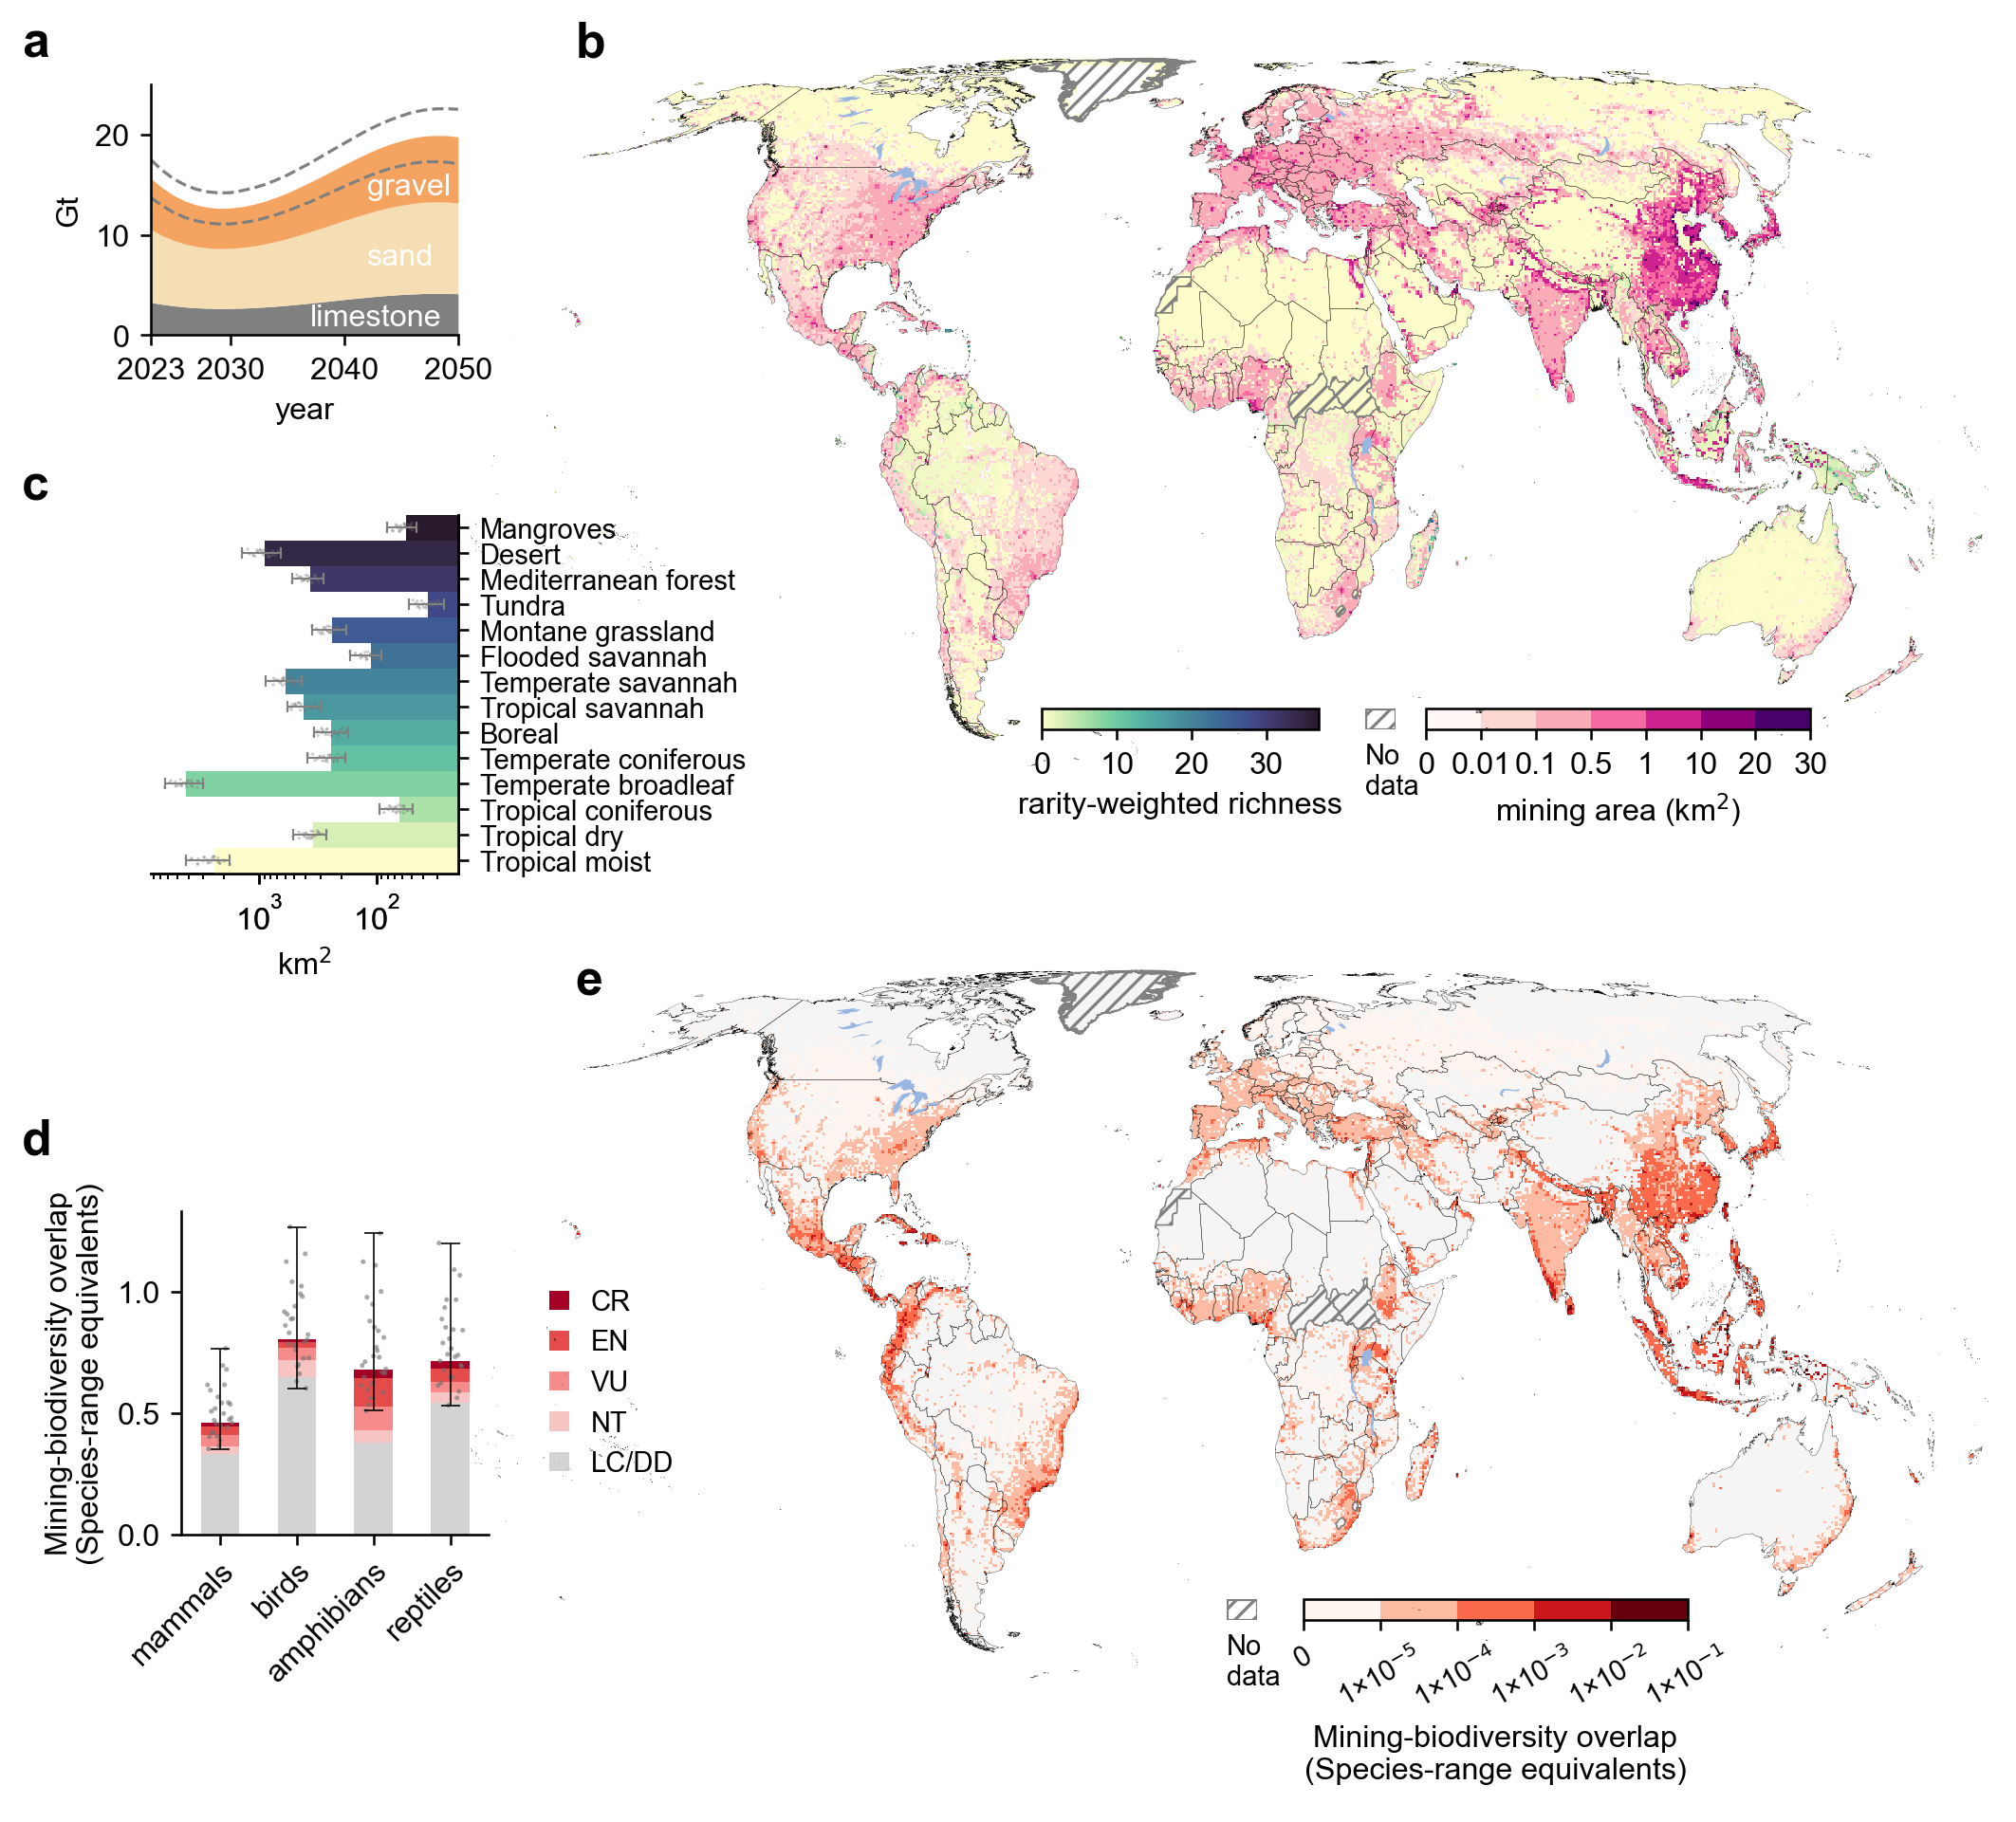

In [ ]:
fig = plt.figure(figsize=(10, 8), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'

# ===================== panels a/b: RWR + mining area =======================
ax1 = plt.subplot(2, 1, 1, projection=ccrs.EckertIV())
ax1.add_feature(cf.LAKES, zorder=20)
world_map_eck4.plot(color='none', edgecolor='k', lw=0.1, ax=ax1, zorder=10)
im1 = ax1.imshow(np.where(rarity_weighted_richness_50km > 0, rarity_weighted_richness_50km, np.nan), vmin=0, vmax=np.max(rarity_weighted_richness_50km), cmap=cm.deep, interpolation='nearest', origin='upper', extent=display_extent_50km, zorder=1)
im2 = ax1.imshow(np.where(mining_area_2050_BAU_50km, mining_area_2050_BAU_50km, np.nan), cmap='RdPu', interpolation='nearest', norm=norm_MA_50km, origin='upper', extent=display_extent_50km, zorder=5, alpha=1.0)
cax1 = ax1.inset_axes([0.38, 0.05, 0.18, 0.03])
cax2 = ax1.inset_axes([0.63, 0.05, 0.25, 0.03])
cbar1 = fig.colorbar(im1, cax=cax1, orientation='horizontal', label='rarity-weighted richness')
cbar2 = fig.colorbar(im2, cax=cax2, orientation='horizontal', label='mining area (km$^{2}$)')

nodata_area.plot(hatch='////', linewidth=0.5, color='none', edgecolor='grey', zorder=15, ax=ax1)
cax3 = ax1.inset_axes([0.59, 0.05, 0.02, 0.03])
cax3.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='grey', hatch='////'))
cax3.axis('off')
cax3.text(0.0, -3.0, 'No\ndata', fontsize=9)

formatter = FuncFormatter(lambda x, _: f'{x:.2g}')   # 2 significant figures
cbar2.ax.xaxis.set_major_formatter(formatter)
cbar2.formatter = formatter
cbar2.update_ticks()
cbar1.set_ticks([0, 10, 20, 30])
ax1.set_ylim(-7.2e6, 8.6e6)
ax1.axis('off')

ax1_1 = ax1.inset_axes([-.20, 0.60, 0.20, 0.35], zorder=1)
global_extraction_BAU_med.plot.area(stacked=True, color=['grey', 'wheat', 'sandybrown'], lw=0, xlim=(2023, 2050), ylim=(0, 25), ax=ax1_1, ylabel='Gt', legend=False)
global_extraction_BAU_total['lower'].plot(ls='--', lw=1.0, color='grey', ax=ax1_1)
global_extraction_BAU_total['upper'].plot(ls='--', lw=1.0, color='grey', ax=ax1_1)
ax1_1.set_xlim([2023, 2050])
ax1_1.set_xticks([2023, 2030, 2040, 2050])
ax1_1.set_yticks([0, 10, 20])
ax1_1.spines['top'].set_visible(False)
ax1_1.spines['right'].set_visible(False)
ax1_1.text(2037, 1, 'limestone', c='w')
ax1_1.text(2042, 7, 'sand', c='w')
ax1_1.text(2042, 14, 'gravel', c='w', zorder=10)

ax1_2 = ax1.inset_axes([-.20, -0.15, 0.20, 0.50], zorder=1)
ax1_3 = ax1_2.twinx()
ax1_3.barh([i for i in range(14)], MA_abs_by_biome, color=colors, height=1.0)
ax1_3.invert_xaxis()

y = np.arange(len(MA_abs_by_biome))
x = np.array(MA_abs_by_biome)
lower = x - np.array(MA_abs_by_biome_lower)
upper = np.array(MA_abs_by_biome_upper) - x
xerr = np.vstack([lower, upper])
biome_errorbars = ax1_3.errorbar(x, y, xerr=xerr, fmt='none', ecolor='grey', elinewidth=0.65, capsize=2, capthick=0.65, zorder=20)

ax1_3.set_yticks([i for i in range(0, 14)], biome_labels, rotation=0, fontsize=9)
ax1_3.set_ylim(-0.5, 13.5)
ax1_3.spines['top'].set_visible(False)
ax1_2.spines['top'].set_visible(False)
ax1_3.spines['left'].set_visible(False)
ax1_2.spines['left'].set_visible(False)
ax1_2.set_yticks([])
ax1_3.xaxis.set_visible(True)
ax1_3.set_xlabel('km$^{2}$')
ax1_3.set_xscale('log')
# The central combination is included in the 27 points below.

# Overlay all 27 outputs per biome within the min-max sensitivity envelope.
# Narrow vertical jitter forms a strip; horizontal positions are exact.
point_rng = np.random.default_rng(20260930)
point_offsets = np.linspace(-0.16, 0.16, len(DRA_COMBINATIONS))
factorial_point_artists = []
for row, biome in enumerate(biome_types):
    points = ax1_3.scatter(
        MA_factorial_by_biome[biome].to_numpy(),
        row + point_rng.permutation(point_offsets),
        s=1.0, facecolors='#707070', edgecolors='none', linewidths=0,
        alpha=0.35, zorder=12)
    factorial_point_artists.append(points)


# ===================== panels c/d: mining-biodiversity overlap =============
ax2 = plt.subplot(2, 1, 2, projection=ccrs.EckertIV())
world_map_eck4.plot(color='whitesmoke', edgecolor='none', lw=0.0, ax=ax2, zorder=1)
world_map_eck4.plot(color='none', edgecolor='k', lw=0.1, ax=ax2, zorder=10)
ax2.add_feature(cf.LAKES, zorder=20)

ticks = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
norm_SL_percent = BoundaryNorm(ticks, 256)

im4 = ax2.imshow(np.where(affected_species_range_BAU_50km == 0, np.nan, affected_species_range_BAU_50km), interpolation='nearest', cmap='Reds', norm=norm_SL_percent, origin='upper', extent=display_extent_50km, zorder=5)

cax3 = ax2.inset_axes([0.55, 0.08, 0.25, 0.03])
cbar3 = fig.colorbar(im4, cax=cax3,  orientation='horizontal', label='Mining-biodiversity overlap\n(Species-range equivalents)')

# scientific-notation tick formatter
def sci_fmt(x, pos):
    if x == 0:
        return "0"
    s = f"{x:.0e}"
    base, exp = s.split('e')
    return f"{base}×10$^{{{int(exp)}}}$"

cbar3.ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
for label in cbar3.ax.get_xticklabels():
    label.set_rotation(30)
    label.set_fontsize(9)


ax2.set_ylim(-7.2e6, 8.6e6)
ax2.axis('off')
nodata_area.plot(hatch='////', linewidth=0.5, color='none', edgecolor='grey', zorder=15, ax=ax2)

cax4 = ax2.inset_axes([0.50, 0.08, 0.02, 0.03])
cax4.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='grey', hatch='////'))
cax4.axis('off')
cax4.text(0.0, -3.0, 'No\ndata', fontsize=9)


ax2_1 = ax2.inset_axes([-.18, 0.20, 0.20, 0.45], zorder=1)
ASR_by_taxon_BAU.T.plot.bar(stacked=True, color=['lightgrey', '#f7c4c4', '#f58b8b', '#e54b4b', '#a50026'], ax=ax2_1)

ax2_1.set_xticklabels(['mammals', 'birds', 'amphibians', 'reptiles'], rotation=45, ha='right', rotation_mode='anchor')
handles, labels = ax2_1.get_legend_handles_labels()
ax2_1.legend(handles[::-1], labels[::-1], loc='lower center', bbox_to_anchor=(1.4, 0.1), ncol=1, fontsize=9, frameon=False, handlelength=0.7, handleheight=0.7)
ax2_1.set_yticks([0, 0.5, 1.0, 1.5, 2.0])
ax2_1.set_ylabel('Mining-biodiversity overlap\n(Species-range equivalents)')
ax2_1.spines['top'].set_visible(False)
ax2_1.spines['right'].set_visible(False)
x = np.arange(len(ASR_total_by_taxon))
y = ASR_total_by_taxon.to_numpy()
lower = y - ASR_total_by_taxon_lower.to_numpy()
upper = ASR_total_by_taxon_upper.to_numpy() - y
yerr = np.vstack([lower, upper])
taxon_errorbars = ax2_1.errorbar(x, y, yerr=yerr, fmt='none', ecolor='k',
    elinewidth=0.5, capsize=3, capthick=0.5, zorder=20)

# Panel d has more space: slightly larger, clearer grey points below error bars.
# Horizontal jitter forms a narrow strip; vertical positions are exact totals.
taxon_point_rng = np.random.default_rng(20260930)
taxon_point_offsets = np.linspace(-0.16, 0.16, len(DRA_COMBINATIONS))
taxon_factorial_point_artists = []
for column, taxon in enumerate(ASR_by_taxon_BAU.columns):
    points = ax2_1.scatter(
        column + taxon_point_rng.permutation(taxon_point_offsets),
        ASR_factorial_by_taxon[taxon].to_numpy(),
        s=2.5, facecolors='#707070', edgecolors='none', linewidths=0,
        alpha=0.60, zorder=12)
    taxon_factorial_point_artists.append(points)

fig.text(0, 0.99, 'a', fontdict={'size':16, 'weight': 'semibold'})
fig.text(0, 0.74, 'c', fontdict={'size':16, 'weight': 'semibold'})
fig.text(0.25, 0.99, 'b', fontdict={'size':16, 'weight': 'semibold'})
fig.text(0, 0.37, 'd', fontdict={'size':16, 'weight': 'semibold'})
fig.text(0.25, 0.46, 'e', fontdict={'size':16, 'weight': 'semibold'})

# Final-size export: 180 mm refers to the cropped output, not the working canvas.
# pypdf preserves editable text/vector objects while scaling the complete page.
from io import BytesIO
from pypdf import PdfReader, PdfWriter

FINAL_WIDTH_MM = 180.0
FINAL_PNG_DPI = 300
FIGURES.mkdir(parents=True, exist_ok=True)
# Freeze the layout once, then use one crop for both formats.
fig.canvas.draw()
fig.set_layout_engine('none')
export_bbox = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.1)
pdf_buffer = BytesIO()
with mpl.rc_context({'pdf.fonttype': 42, 'ps.fonttype': 42}):
    fig.savefig(pdf_buffer, format='pdf', dpi=600, bbox_inches=export_bbox)
pdf_buffer.seek(0)
pdf_reader = PdfReader(pdf_buffer)
page = pdf_reader.pages[0]
export_scale = (FINAL_WIDTH_MM / 25.4 * 72) / float(page.mediabox.width)
page.scale_by(export_scale)
pdf_writer = PdfWriter()
pdf_writer.add_page(page)
pdf_writer.add_metadata({'/Title': 'Figure 1', '/Subject': 'Final width: 180 mm'})
with FIG_OUT.with_suffix('.pdf').open('wb') as pdf_file:
    pdf_writer.write(pdf_file)
# Render at the same scale; store the final physical resolution in the PNG.
fig.savefig(FIG_OUT.with_suffix('.png'), dpi=FINAL_PNG_DPI * export_scale,
            bbox_inches=export_bbox, pil_kwargs={'dpi': (FINAL_PNG_DPI, FINAL_PNG_DPI)})
# Check the delivered PDF itself, so later layout changes cannot restore oversize output.
final_page = PdfReader(FIG_OUT.with_suffix('.pdf')).pages[0]
assert abs(float(final_page.mediabox.width) * 25.4 / 72 - FINAL_WIDTH_MM) < 1e-6
if mpl.get_backend().lower() != 'agg':
    plt.show()

### In main text

Restore the economy-first convention: take the 2.5th, 50th and 97.5th
percentiles for each economy, material and year, then sum the corresponding
percentiles across economies (and years/materials for cumulative totals).
Panel a, its Source Data and extraction text use these same summaries.
The aggregate bounds are sums of local percentile endpoints, not a 95%
probability interval of a simulated global total. Spatial mining-area and
biodiversity-risk summaries retain their existing 27-combination definitions.


In [ ]:
# The same economy-first percentile summaries are used by panel a and text.
text_2050 = {material: np.array([
    global_extraction_BAU_low.loc[2050, material],
    global_extraction_BAU_med.loc[2050, material],
    global_extraction_BAU_upp.loc[2050, material],
]) for material in ['sand', 'gravel', 'limestone']}

def annual_extraction_text(material):
    lower, central, upper = text_2050[material]
    return f'{central:.1f} Gt yr-1 (uncertainty range: {lower:.1f}–{upper:.1f} Gt yr-1)'

print('As a result, global demand for sand, gravel, and limestone embodied in '
      'concrete and mortar is projected to reach '
      f'{annual_extraction_text("sand")}, {annual_extraction_text("gravel")}, '
      f'and {annual_extraction_text("limestone")} by 2050, respectively (Figure 1a).')


As a result, global demand for sand, gravel, and limestone embodied in concrete and mortar is projected to reach 9.0 Gt yr-1 (uncertainty range: 8.2–9.9 Gt yr-1), 6.6 Gt yr-1 (uncertainty range: 5.8–7.4 Gt yr-1), and 4.1 Gt yr-1 (uncertainty range: 3.0–5.2 Gt yr-1) by 2050, respectively (Figure 1a).


In [ ]:
# Sum the same annual economy-first estimates used by panel a.
d_2, d_1, d_3 = global_extraction_BAU_total[['lower', 'median', 'upper']].sum().to_numpy()
text_fig2 = pd.read_csv(RESULTS / 'Data-for-Fig-2a.csv', index_col=0)
np.testing.assert_allclose(
    [d_2, d_1, d_3], text_fig2.loc['BAU', ['total_l', 'total', 'total_u']].to_numpy(float),
    rtol=1e-10, atol=1e-10, err_msg='Figure 1 and Figure 2 use different extraction summaries.')

d_4 = MA_factorial_global.loc[DRA_MID]
d_5 = MA_factorial_global.min()
d_6 = MA_factorial_global.max()
print(
    f'Under the BAU scenario, cumulative global extraction of {d_1:.0f} Gt '
    f'(uncertainty range: {d_2:.0f}–{d_3:.0f} Gt) between 2023 and 2050 is projected to disturb '
    f'at least an additional {d_4:,.0f} km2 '
    f'(uncertainty range: {d_5:,.0f}–{d_6:,.0f} km2) of land by 2050 (Figure 1b).'
)
order = np.argsort(MA_abs_by_biome)[::-1]
biome_parts = ', '.join(f'{biome_labels[i]} ({MA_abs_by_biome[i]:,.0f} km2, '
                        f'{MA_prop_by_biome[i]:.0f}%)' for i in order[:4])
print(f'The largest projected expansion occurs in {biome_parts} (Figure 1c).')


Under the BAU scenario, cumulative global extraction of 446 Gt (uncertainty range: 390–503 Gt) between 2023 and 2050 is projected to disturb at least an additional 10,308 km2 (uncertainty range: 7,498–16,123 km2) of land by 2050 (Figure 1b).
The largest projected expansion occurs in Temperate broadleaf (4,191 km2, 41%), Tropical moist (2,434 km2, 24%), Desert (895 km2, 9%), Temperate savannah (598 km2, 6%) (Figure 1c).


In [ ]:
b_1 = ASR_factorial_global.loc[DRA_MID]
b_2 = ASR_factorial_global.min()
b_3 = ASR_factorial_global.max()
b_4 = (ASR_by_taxon_BAU.sum() / ASR_by_taxon_BAU.sum().sum())['mammals'] * 100
b_5 = ASR_by_taxon_BAU.sum()['mammals']
b_6 = (ASR_by_taxon_BAU.sum() / ASR_by_taxon_BAU.sum().sum())['birds'] * 100
b_7 = ASR_by_taxon_BAU.sum()['birds']
b_8 = (ASR_by_taxon_BAU.sum() / ASR_by_taxon_BAU.sum().sum())['amphibians'] * 100
b_9 = ASR_by_taxon_BAU.sum()['amphibians']
b_10 = (ASR_by_taxon_BAU.sum() / ASR_by_taxon_BAU.sum().sum())['reptiles'] * 100
b_11 = ASR_by_taxon_BAU.sum()['reptiles']

print(f'Globally, projected mining area expansion overlaps a total of {b_1:.1f} (uncertainty range: {b_2:.1f}-{b_3:.1f}) species-range equivalents. \n\
Of this total, mammals account for {b_4:.0f}% ({b_5:.1f} species-range equivalent), \n\
birds {b_6:.0f}% ({b_7:.1f} species-range equivalent), amphibians {b_8:.0f}% ({b_9:.1f} species-range equivalents), \n\
and reptiles {b_10:.0f}% ({b_11:.1f} species-range equivalent)')

Globally, projected mining area expansion overlaps a total of 2.7 (uncertainty range: 2.0-4.5) species-range equivalents. 
Of this total, mammals account for 17% (0.5 species-range equivalent), 
birds 30% (0.8 species-range equivalent), amphibians 26% (0.7 species-range equivalents), 
and reptiles 27% (0.7 species-range equivalent)


In [ ]:
c_1 = (ASR_by_taxon_BAU.sum(axis=1) / ASR_by_taxon_BAU.sum().sum())['CR'] * 100
c_2 = (ASR_by_taxon_BAU.sum(axis=1) / ASR_by_taxon_BAU.sum().sum())['EN'] * 100
c_3 = (ASR_by_taxon_BAU.sum(axis=1) / ASR_by_taxon_BAU.sum().sum())['VU'] * 100
c_4 = (ASR_by_taxon_BAU.sum(axis=1) / ASR_by_taxon_BAU.sum().sum())['NT'] * 100

print(f'Impacts span all IUCN Red List categories, \n\
with critically endangered species contributing {c_1:.0f}% of the total overlap, \n\
endangered species {c_2:.0f}%, vulnerable species {c_3:.0f}%, and near-threatened species {c_4:.0f}%')

Impacts span all IUCN Red List categories, 
with critically endangered species contributing 3% of the total overlap, 
endangered species 9%, vulnerable species 9%, and near-threatened species 7%
